# Activity: Should We Trust the Alarm? — FreshKart Cold-Chain Case

**Unit 4 · AI-Assisted Visualization · AI-Assisted Pattern and Anomaly Visualization**
Visualization of Data, Understanding and Interpretation (UE24CS342AA9)

---

## The case

FreshKart's dark stores keep frozen food in **8 freezers** (one per store in Bengaluru, Pune and Hyderabad). Each freezer reports its temperature every hour. Last month FreshKart bought **ColdSense**, an AI service that scores every reading for "anomaly" and raises an alert when the score is **≥ 0.5**.

Cold-chain lead **Ravi** has six weeks of readings, the ColdSense scores, and the **maintenance log** (what technicians actually found). His technicians are tired of being sent out at night. He asks:

> *"Is ColdSense's alert feed trustworthy? Which alerts should my team chase, and what is it missing?"*

**You are the analyst.** Use the data and the visualizations to verify, correct or reject what the vendor claims.

**Ground rules (from the lecture):** an AI score is a *derived attribute*: look at it, don't only threshold it · flags are **candidates, not conclusions** · report precision and recall, not accuracy · scale emphasis to confidence.

**How to work:** run the notebook top to bottom. Complete every cell marked `# TODO` (replace `None` with your code or answer) and write in the cells marked **✏️ Your answer**. Cells that depend on your TODO will tell you if something is still missing.

### The data: `freshkart_coldchain.csv` (synthetic)

| Column | Meaning |
|---|---|
| `timestamp` | hour of the reading (1 Aug – 11 Sep 2026) |
| `city`, `store_id`, `freezer_id` | where the freezer is |
| `temp_c` | freezer temperature (°C); normal is about −18 °C |
| `door_opens` | number of door openings in that hour (busy by day, quiet at night) |
| `compressor_kw` | compressor power draw (kW) |
| `ai_score`, `ai_flag` | ColdSense anomaly score (0–1) and alert (1 if score ≥ 0.5) |
| `confirmed_fault`, `fault_type` | from the maintenance log: 1 if technicians confirmed a real fault in that hour, and what it was |

**Domain note from the maintenance team:** every freezer runs an automatic **defrost cycle from 02:00 to 04:00** each night. The heater warms the coil, so the temperature rises for those two hours. That is normal.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (6, 3.2), "axes.spines.top": False, "axes.spines.right": False})
GREY, ACCENT, BLUE = "#bdbdbd", "#d95f02", "#4c78a8"

def ready(*vals):
    """Helper: tells you if a TODO above is still unanswered."""
    ok = all(v is not None for v in vals)
    if not ok:
        print("⚠ Complete the TODO cell(s) above first, then re-run this cell.")
    return ok

df = pd.read_csv("freshkart_coldchain.csv", parse_dates=["timestamp"])
df["hour"] = df["timestamp"].dt.hour
df.head()

,timestamp,city,store_id,freezer_id,temp_c,door_opens,compressor_kw,ai_score,ai_flag,confirmed_fault,fault_type,hour
0,2026-08-01,Bengaluru,B1,FZ-B1,-18.1,0,1.29,0.000,0,0,NaN,0
1,2026-08-01,Bengaluru,B2,FZ-B2,-18.7,0,1.16,0.000,0,0,NaN,0
2,2026-08-01,Bengaluru,B3,FZ-B3,-17.7,0,1.21,0.000,0,0,NaN,0
3,2026-08-01,Hyderabad,H1,FZ-H1,-17.8,0,1.30,0.037,0,0,NaN,0
4,2026-08-01,Hyderabad,H2,FZ-H2,-18.2,0,1.32,0.035,0,0,NaN,0


## ColdSense's monthly report (to be validated)

| # | Vendor statement |
|---|---|
| 1 | "ColdSense is **97.9% accurate**, so its alerts can be trusted." |
| 2 | "**Most faults happen around 2 am.** We recommend a night technician." |
| 3 | "**All 10 compressor trips** in the period were caught." |
| 4 | "Freezer **FZ-H2 ran without a single fault** in August." |
| 5 | "A reading of **−14 °C is abnormal** for any freezer, at any time." |
| 6 | "An alert with a score of **0.92 means a 92% chance** of a real fault." |
| 7 | "The **default threshold of 0.5** is the best setting for FreshKart." |
| 8 | "A new FZ-B1 reading of **−15.9 °C at 14:00** is **15 standard errors** above normal: a definite fault." |

---
## Part 1 · Data abstraction: items, attributes and derived attributes

Munzner: before choosing a view, ask what the **items** and **attributes** are. The AI does not change the items; it **derives** new attributes.

In [2]:
derived_cols = ["ai_score", "ai_flag"]
n_alerts = int((df["ai_flag"] == 1).sum())
fault_rate_pct = round(df["confirmed_fault"].mean() * 100, 2)

if ready(derived_cols, n_alerts, fault_rate_pct):
    print(f"derived: {derived_cols} | alerts: {n_alerts} | faults: {df.confirmed_fault.sum()} of {len(df)} rows ({fault_rate_pct}%)")
    display(df[df.confirmed_fault == 1].groupby("fault_type").size().rename("fault hours"))

derived: ['ai_score', 'ai_flag'] | alerts: 159 | faults: 46 of 8064 rows (0.57%)


fault_type
compressor trip         10
defrost heater stuck    11
sensor frozen           25
Name: fault hours, dtype: int64

**✏️ Your answer (Part 1):** `ai_score` is quantitative and `ai_flag` is binary. Which **visual channel** suits each, and what information does the flag throw away that the score keeps?

*Your answer:*

`ai_score` is quantitative, so I'd use position on an aligned axis (e.g. a score line under the temperature chart) or a continuous colour/size scale, because people compare position best. `ai_flag` is just yes/no, so a categorical channel like a marker (present/absent) or a single colour hue is enough. The flag throws away how confident ColdSense was: 0.51 and 0.99 look identical, 0.49 gets nothing at all, and you can't change the threshold later. The score keeps all of that.

---
## Part 2 · Distributions: bin width and the score distribution

### 2a · Temperature histogram

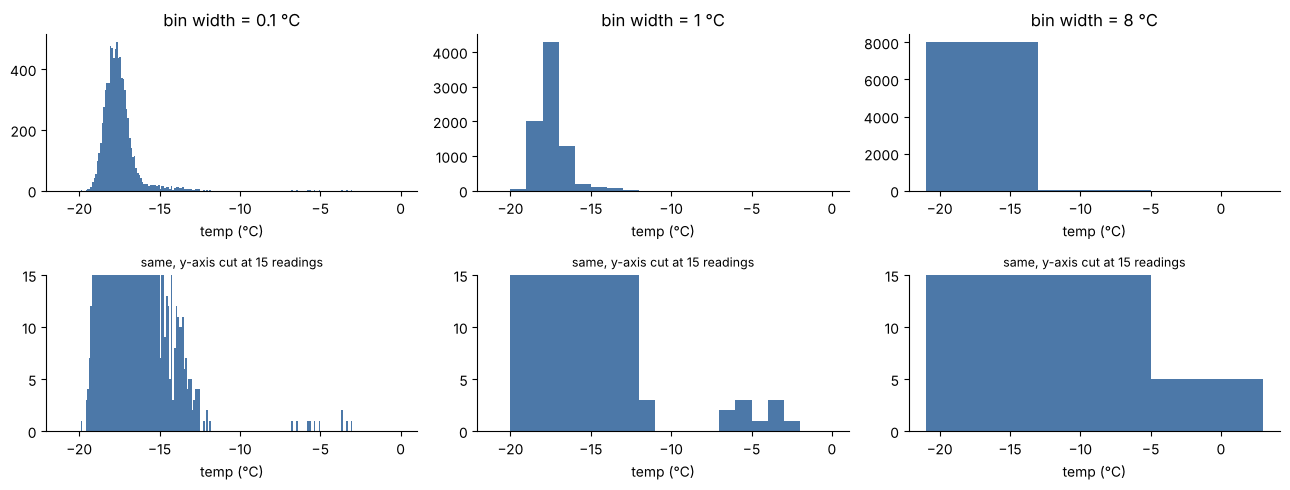

[0.1, 1] 10


In [3]:
fig, axes = plt.subplots(2, 3, figsize=(13, 5))
for col, w in enumerate([0.1, 1, 8]):
    for row, top in enumerate([None, 15]):
        ax = axes[row, col]
        ax.hist(df["temp_c"], bins=np.arange(-21, 0 + w, w), color=BLUE)
        if top: ax.set_ylim(0, top); ax.set_title(f"same, y-axis cut at {top} readings", fontsize=9)
        else: ax.set_title(f"bin width = {w} °C")
        ax.set_xlabel("temp (°C)")
plt.tight_layout(); plt.show()

warm_tail_visible_bins = [0.1, 1]
n_warm_readings = int((df["temp_c"] > -8).sum())
print(warm_tail_visible_bins, n_warm_readings)

### 2b · Look at the AI scores before trusting the cut-off
Wilke: compare groups with overlapping densities, not stacked histograms.

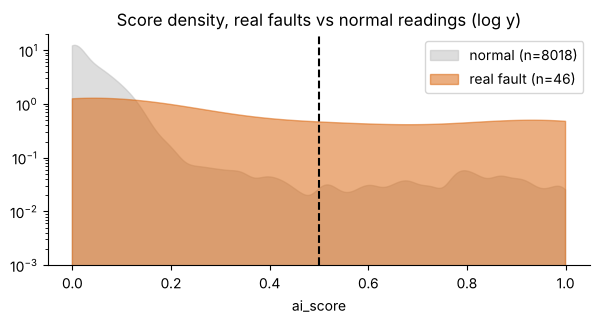

In [4]:
xs = np.linspace(0, 1, 300)
fig, ax = plt.subplots(figsize=(7, 3))
for lab, col in [(0, GREY), (1, ACCENT)]:
    s = df.loc[df.confirmed_fault == lab, "ai_score"]
    ax.fill_between(xs, stats.gaussian_kde(s)(xs), color=col, alpha=.5, label=f"{'real fault' if lab else 'normal'} (n={len(s)})")
ax.axvline(0.5, color="k", ls="--"); ax.set_yscale("log"); ax.set_ylim(1e-3, 20)
ax.set_xlabel("ai_score"); ax.legend(); ax.set_title("Score density, real faults vs normal readings (log y)")
plt.show()

scores_separate_faults = False

**✏️ Your answer (Part 2):** Why is a histogram "a parameterised algorithm", and what would you tell a colleague who says *"the 8 °C histogram shows no anomalies"*?

*Your answer:*

A histogram is a parameterised algorithm because the picture depends on choices we make (bin width, where the bins start, the y-axis limit), so the same data can look different with different settings. To the colleague I'd say: the 8 °C bins are too wide, they put the 10 readings warmer than -8 °C into one bar with the -13 to -12 °C readings so nothing looks odd. With 0.1 or 1 °C bins and the y-axis cut at 15 you can see the warm readings as a separate group. So "no anomalies" in a coarse histogram doesn't mean there are none, I'd try narrower bins and a log y-axis before saying that.

---
## Part 3 · Outlier rules on a short window (vendor statement 3)

Ten consecutive readings from **FZ-P1**, 12 Aug 06:00–15:00. One of them is a compressor trip.

In [5]:
window = df[(df.freezer_id == "FZ-P1") & (df.timestamp >= "2026-08-12 06:00") & (df.timestamp < "2026-08-12 16:00")]
v = window["temp_c"].values
print(window[["timestamp", "temp_c", "fault_type"]].to_string(index=False))

z_max = np.abs((v - v.mean()) / np.std(v, ddof=1)).max()
q1, q3 = np.percentile(v, [25, 75])
upper_fence = q3 + 1.5 * (q3 - q1)

if ready(z_max, upper_fence):
    print(f"largest |z| = {z_max:.2f} -> flagged by |z| > 3? {z_max > 3}")
    print(f"upper IQR fence = {upper_fence:.2f} °C -> trip flagged by IQR rule? {v.max() > upper_fence}")
    print(f"largest |z| possible with n = {len(v)}: {(len(v) - 1) / np.sqrt(len(v)):.2f}")

          timestamp  temp_c      fault_type
2026-08-12 06:00:00   -17.5             NaN
2026-08-12 07:00:00   -18.2             NaN
2026-08-12 08:00:00   -17.4             NaN
2026-08-12 09:00:00   -17.7             NaN
2026-08-12 10:00:00   -16.6             NaN
2026-08-12 11:00:00    -3.6 compressor trip
2026-08-12 12:00:00   -17.0             NaN
2026-08-12 13:00:00   -16.8             NaN
2026-08-12 14:00:00   -17.7             NaN
2026-08-12 15:00:00   -17.7             NaN
largest |z| = 2.83 -> flagged by |z| > 3? False
upper IQR fence = -15.58 °C -> trip flagged by IQR rule? True
largest |z| possible with n = 10: 2.85


**✏️ Your answer (Part 3):** Explain in two sentences why the z-score rule missed the trip here (use the word *masking*) and why the IQR rule did not.

*Your answer:*

The z-score rule missed it because in a short window of 10 readings the trip itself (-3.6 °C) drags up the mean and the SD, so its own z-score gets shrunk to 2.83 (masking), and with n = 10 the biggest |z| you can ever get is 2.85, so it can never pass 3. The IQR rule uses quartiles, which are not pulled by a single extreme value, so the upper fence stays at about -15.6 °C and the trip is far above it.

---
## Part 4 · How good is ColdSense? (vendor statement 1)

In [6]:
flag = df.ai_flag == 1
real = df.confirmed_fault == 1

TP = int((flag & real).sum())
FP = int((flag & ~real).sum())
FN = int((~flag & real).sum())
TN = int((~flag & ~real).sum())

if ready(TP, FP, FN, TN):
    display(pd.DataFrame([[TP, FN], [FP, TN]], index=["real fault", "normal"], columns=["alert", "no alert"]))

,alert,no alert
real fault,16,30
normal,143,7875


In [7]:
precision = TP / (TP + FP)
recall = TP / (TP + FN)
f1 = 2 * precision * recall / (precision + recall)
accuracy = (TP + TN) / len(df)
flag_nothing_accuracy = (~real).mean()

if ready(precision, recall, f1, accuracy, flag_nothing_accuracy):
    print(f"precision = {precision:.2f} | recall = {recall:.2f} | F1 = {f1:.2f} | accuracy = {accuracy:.1%} | never-alert accuracy = {flag_nothing_accuracy:.1%}")

precision = 0.10 | recall = 0.35 | F1 = 0.16 | accuracy = 97.9% | never-alert accuracy = 99.4%


**✏️ Your answer (Part 4):** Rewrite vendor statement 1 so it is honest. Use precision and recall, and say in plain words what they mean for Ravi's technicians (how many call-outs are wasted, how many faults are missed).

*Your answer:*

*"ColdSense is 97.9% accurate overall, but that's mostly because 99.4% of readings are normal (a detector that never alerts would score 99.4%). Its precision is only 0.10, so about 9 out of 10 alerts are false alarms and technicians waste their call-outs, and its recall is only 0.35, so about 2 out of every 3 real faults are never alerted."*

(16 of its 159 alerts were real, and it caught 16 of the 46 fault hours.)

---
## Part 5 · Thresholds and costs (vendor statement 7)

A missed fault can spoil a freezer of stock (cost ≈ **40** units); a false call-out costs **1** unit of technician time.

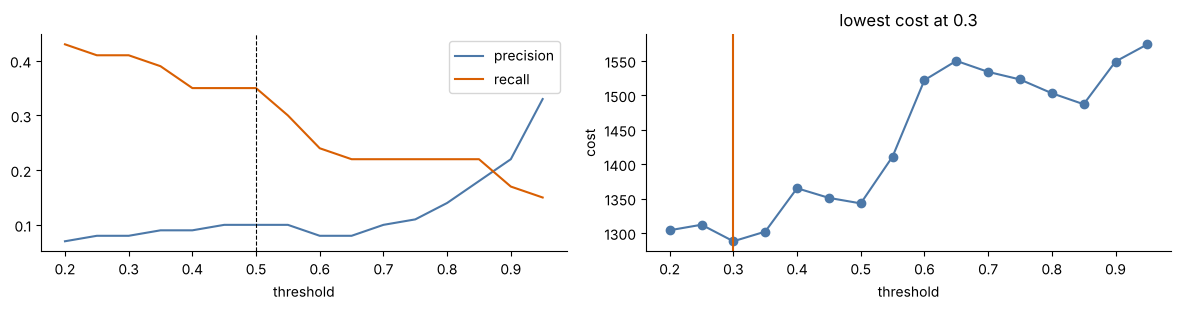

,threshold,TP,FP,FN,precision,recall,cost
0,0.20,20,264,26,0.07,0.43,1304
1,0.25,19,232,27,0.08,0.41,1312
2,0.30,19,208,27,0.08,0.41,1288
3,0.35,18,182,28,0.09,0.39,1302
4,0.40,16,165,30,0.09,0.35,1365
5,0.45,16,151,30,0.10,0.35,1351
6,0.50,16,143,30,0.10,0.35,1343
7,0.55,14,131,32,0.10,0.30,1411
8,0.60,11,122,35,0.08,0.24,1522
9,0.65,10,110,36,0.08,0.22,1550


In [8]:
grid = np.round(np.arange(0.20, 0.96, 0.05), 2)
sweep = pd.DataFrame({"threshold": grid})
sweep["TP"] = [((df.ai_score >= g) & real).sum() for g in grid]
sweep["FP"] = [((df.ai_score >= g) & ~real).sum() for g in grid]
sweep["FN"] = real.sum() - sweep["TP"]
sweep["precision"] = (sweep.TP / (sweep.TP + sweep.FP)).round(2)
sweep["recall"] = (sweep.TP / real.sum()).round(2)

sweep["cost"] = 40 * sweep["FN"] + 1 * sweep["FP"]
best_threshold = sweep.loc[sweep["cost"].astype(float).idxmin(), "threshold"]

if ready(best_threshold) and sweep["cost"].notna().all():
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
    ax[0].plot(sweep.threshold, sweep.precision, color=BLUE, label="precision"); ax[0].plot(sweep.threshold, sweep.recall, color=ACCENT, label="recall")
    ax[0].axvline(0.5, color="k", ls="--", lw=.8); ax[0].legend(); ax[0].set_xlabel("threshold")
    ax[1].plot(sweep.threshold, sweep.cost.astype(float), color=BLUE, marker="o"); ax[1].axvline(best_threshold, color=ACCENT)
    ax[1].set_xlabel("threshold"); ax[1].set_ylabel("cost"); ax[1].set_title(f"lowest cost at {best_threshold}")
    plt.tight_layout(); plt.show()
    display(sweep)

**✏️ Your answer (Part 5):** Even at the best threshold, recall stays low. Why can no threshold fix this detector? (Hint: look at *which* faults are never scored high.)

*Your answer:*

Because the faults it misses are the "sensor frozen" ones (25 of the 46 fault hours). A frozen sensor just shows a steady -18 °C, which looks perfectly normal if you score each reading on its own, so these readings get a score near 0 no matter what threshold we choose. Lowering the threshold only adds false alarms (264 at 0.20) and recall barely moves (20 of 46). The cheapest threshold here is 0.30, not 0.50, but even that only helps a bit.

---
## Part 6 · Where do the errors come from?

### 6a · When do the false alarms happen? (vendor statement 2)

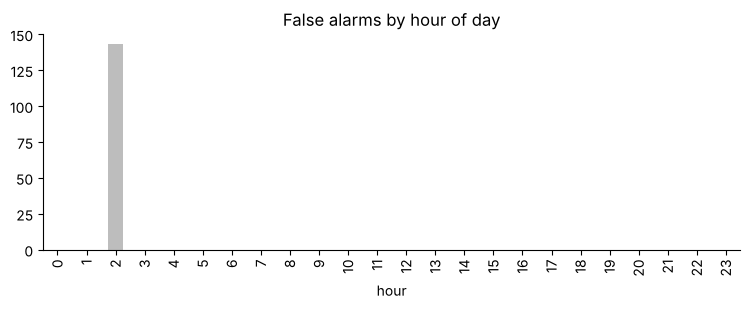

100% of false alarms happen at 2:00


In [9]:
fp_rows = df[flag & ~real]
fp_rows.groupby("hour").size().reindex(range(24), fill_value=0).plot.bar(color=GREY, title="False alarms by hour of day", figsize=(9, 2.8))
plt.show()

fp_by_hour = fp_rows.groupby("hour").size()
fp_peak_hour = int(fp_by_hour.idxmax())
fp_share_at_peak = fp_by_hour.max() / fp_by_hour.sum()

if ready(fp_peak_hour, fp_share_at_peak):
    print(f"{fp_share_at_peak:.0%} of false alarms happen at {fp_peak_hour}:00")

### 6b · Which faults does ColdSense miss?

In [10]:
caught = df[real].groupby("fault_type")["ai_flag"].agg(caught="sum", fault_hours="size")
caught["recall"] = (caught.caught / caught.fault_hours).round(2)
display(caught)

never_caught_type = 'sensor frozen'
anomaly_kind = 'collective'
print(never_caught_type, '->', anomaly_kind)

,caught,fault_hours,recall
fault_type,,,
compressor trip,10,10,1.00
defrost heater stuck,6,11,0.55
sensor frozen,0,25,0.00


sensor frozen -> collective


### 6c · Contextual anomalies: compare each reading with its own hour

A **context-aware** baseline compares each reading with the same freezer at the same hour of day (median and MAD over the six weeks).

In [11]:
grp = df.groupby(["freezer_id", "hour"])["temp_c"]
df["hour_median"] = grp.transform("median")
df["hour_mad"] = grp.transform(lambda s: 1.4826 * stats.median_abs_deviation(s))

df["z_context"] = (df["temp_c"] - df["hour_median"]) / df["hour_mad"]

if ready(*df["z_context"].head(1)):
    ctx_flag = df["z_context"].astype(float) > 4
    found = df[real & ctx_flag & ~flag]
    print(f"Real faults the context baseline catches but ColdSense missed: {len(found)}")
    display(found[["timestamp", "freezer_id", "temp_c", "hour_median", "z_context", "ai_score", "fault_type"]])
    print(f"False alarms at 02:00 under the context baseline: {(ctx_flag & ~real & (df.hour == 2)).sum()} (ColdSense: {(flag & ~real & (df.hour == 2)).sum()})")

Real faults the context baseline catches but ColdSense missed: 3


,timestamp,freezer_id,temp_c,hour_median,z_context,ai_score,fault_type
1279,2026-08-07 15:00:00,FZ-P2,-14.6,-17.50,4.890058,0.369,defrost heater stuck
4731,2026-08-25 15:00:00,FZ-H1,-14.8,-17.50,6.070417,0.388,defrost heater stuck
6273,2026-09-02 16:00:00,FZ-B2,-15.2,-17.35,4.143300,0.189,defrost heater stuck


False alarms at 02:00 under the context baseline: 0 (ColdSense: 143)


### 6d · Collective anomalies: a run of readings that is abnormal together

                           min                 max  count
freezer_id                                               
FZ-H2      2026-08-20 14:00:00 2026-08-20 22:00:00      9
FZ-P1      2026-09-06 12:00:00 2026-09-06 17:00:00      6


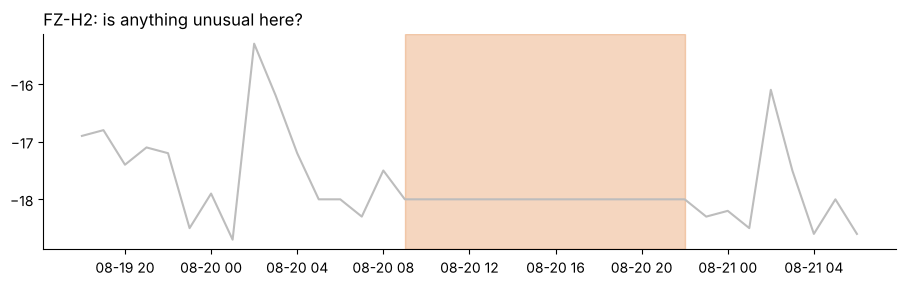

In [12]:
df = df.sort_values(["freezer_id", "timestamp"])
df["roll_sd_6h"] = df.groupby("freezer_id")["temp_c"].transform(lambda s: s.rolling(6).std())

flat = df[df["roll_sd_6h"] < 0.01]

if ready(flat):
    print(flat.groupby("freezer_id")["timestamp"].agg(["min", "max", "count"]))
    h2 = df[(df.freezer_id == "FZ-H2") & (df.timestamp.between("2026-08-19 18:00", "2026-08-21 06:00"))]
    fig, ax = plt.subplots(figsize=(11, 2.8))
    ax.plot(h2.timestamp, h2.temp_c, color=GREY)
    # highlight the whole flat span (rolling window is 6h, so the flat run started 5 hours before the first flagged row)
    h2_flat = flat[flat["freezer_id"] == "FZ-H2"]
    ax.axvspan(h2_flat["timestamp"].min() - pd.Timedelta(hours=5), h2_flat["timestamp"].max(), color=ACCENT, alpha=.25)

    ax.set_title("FZ-H2: is anything unusual here?", loc="left"); plt.show()
df = df.sort_values(["timestamp", "store_id"])

**✏️ Your answer (Part 6):**
(a) Rewrite vendor statement 2. What really happens at 2 am, and what would happen if FreshKart hired a night technician based on the vendor's report?
(b) Is vendor statement 5 true? Use the words *contextual anomaly* and say what a chart must show for a viewer to judge such an alert.
(c) What is wrong with vendor statement 4, and why can a detector that scores readings one at a time never catch this kind of fault?

*Your answer:*

(a) Rewrite: *"ColdSense's alerts cluster at 02:00 because of the nightly defrost cycle, which is normal. All 143 false alarms (100%) happen at 02:00, so they aren't real faults."* A night technician would be sent out every night for nothing (143 false call-outs) and would still miss the real faults, since none of the 46 confirmed fault hours happened at 2 am (they were all between 07:00 and 22:00).

(b) Not true. A reading of -14 °C at 2 am during defrost is normal, while -14 °C at 2 pm is abnormal, so it's a contextual anomaly: whether a value is abnormal depends on its context (the hour of day). The chart has to show that context, for example the usual band for that freezer at that hour (median ± MAD) or the defrost window shaded, so the viewer can judge whether the reading is really unusual. With that context baseline there were 0 false alarms at 02:00 (vs 143 for ColdSense), and it caught 3 heater faults ColdSense missed.

(c) FZ-H2 did have a fault: the log shows its sensor froze at exactly -18.0 °C for 14 hours on 20 Aug (09:00 to 22:00), and the rolling SD was zero. Each of those readings is a normal-looking number, the abnormal thing is that the readings don't change at all, which is a collective anomaly. A detector that scores one reading at a time can never see that, it needs to look at a window of readings (like the rolling SD).

---
## Part 7 · Highlighting, saliency and frequency framing (vendor statement 6)

### 7a · Emphasis scaled to confidence
The vendor's dashboard paints every alert bright red. Implement the lecture's checklist: **≥ 0.90 strong**, **0.70–0.90 moderate**, **0.50–0.70 subtle outline**, **below 0.50 no emphasis** (the data stays visible).

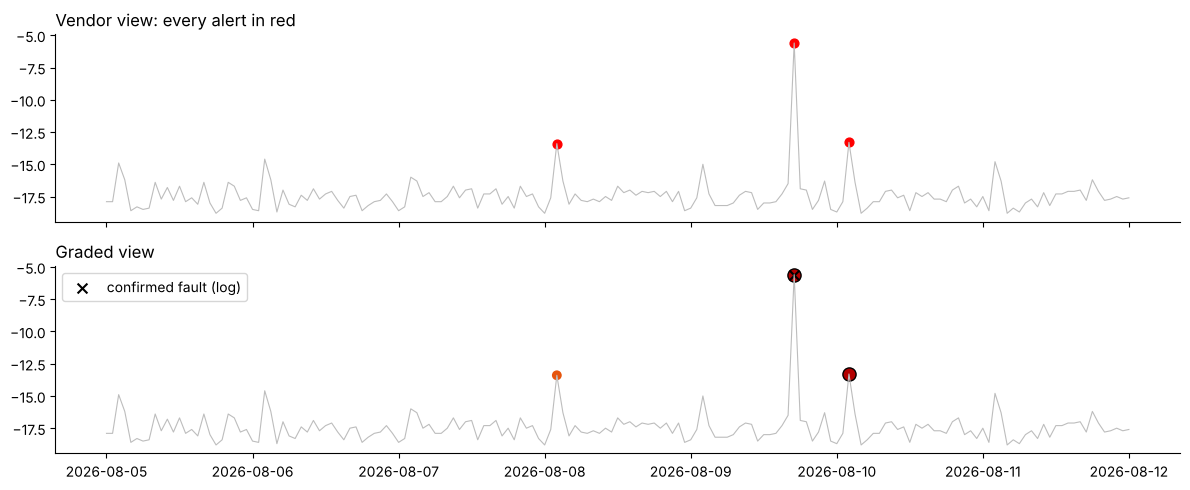

In [13]:
def emphasis(score):
    """Return (colour, marker size, edge colour) for one reading."""
    if score >= 0.90:                      # strong: big dark red filled dot
        return ("#b30000", 90, "black")
    elif score >= 0.70:                    # moderate: medium orange dot
        return ("#e6550d", 50, "none")
    elif score >= 0.50:                    # subtle: small hollow outline only
        return ("white", 35, "#e6550d")
    else:                                  # below 0.5: no emphasis, the data just stays visible
        return (GREY, 5, "none")

week = df[(df.freezer_id == "FZ-B2") & (df.timestamp.between("2026-08-05", "2026-08-12"))]
if ready(emphasis(0.95)):
    fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
    ax[0].plot(week.timestamp, week.temp_c, color=GREY, lw=.8)
    a = week[week.ai_flag == 1]; ax[0].scatter(a.timestamp, a.temp_c, color="red", s=40); ax[0].set_title("Vendor view: every alert in red", loc="left")
    ax[1].plot(week.timestamp, week.temp_c, color=GREY, lw=.8)
    for _, r in week[week.ai_score >= 0.5].iterrows():
        col, size, edge = emphasis(r.ai_score)
        ax[1].scatter(r.timestamp, r.temp_c, color=col, s=size, edgecolors=edge)
    f_ = week[week.confirmed_fault == 1]; ax[1].scatter(f_.timestamp, f_.temp_c, marker="x", color="k", s=50, label="confirmed fault (log)")
    ax[1].legend(loc="upper left"); ax[1].set_title("Graded view", loc="left"); plt.tight_layout(); plt.show()

### 7b · "A score of 0.92 means 92%"? Count it.
Wilke: people read probabilities better as **frequencies**. Of all alerts in a score band, how many were real?

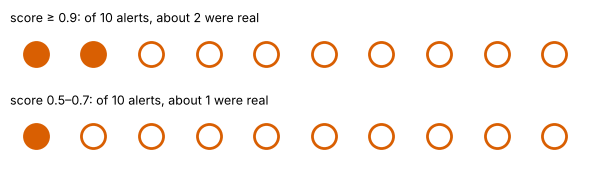

In [14]:
band_hi = df[df.ai_score >= 0.9]
band_lo = df[(df.ai_score >= 0.5) & (df.ai_score < 0.7)]

real_per_10_hi = int(round(band_hi["confirmed_fault"].mean() * 10))
real_per_10_lo = int(round(band_lo["confirmed_fault"].mean() * 10))

if ready(real_per_10_hi, real_per_10_lo):
    fig, ax = plt.subplots(2, 1, figsize=(6, 1.8))
    for a_, k, lab in zip(ax, [real_per_10_hi, real_per_10_lo], ["score ≥ 0.9", "score 0.5–0.7"]):
        for i in range(10): a_.scatter(i, 0, s=300, color=ACCENT if i < k else "white", edgecolors=ACCENT, linewidths=2)
        a_.axis("off"); a_.set_title(f"{lab}: of 10 alerts, about {k} were real", loc="left", fontsize=9)
    plt.tight_layout(); plt.show()

**✏️ Your answer (Part 7):** (a) Why does a red dot at every alert make Ravi's team **more** likely to miss the frozen H2 sensor? Use the words *salience* and *inattentional blindness*. (b) Rewrite vendor statement 6 using frequency framing.

*Your answer:*

(a) With a red dot on every alert, red stops being salient, since 159 red dots (most of them at 02:00) make everything shout so nothing stands out. The frozen H2 sensor has no red dot at all, it's just a flat grey line that looks normal, and the team's attention is pulled to the red dots. Because they're looking for red dots, they don't notice the unflagged flat line, which is inattentional blindness, so they're more likely to miss it.

(b) *"Of every 10 alerts with a score of 0.9 or higher, only about 2 were real faults. Of every 10 alerts with a score between 0.5 and 0.7, only about 1 was real."*

---
## Part 8 · Standard deviation vs standard error (vendor statement 8)

The vendor judged a new FZ-B1 reading of **−15.9 °C at 14:00** against the 14:00 baseline.

In [15]:
base = df[(df.freezer_id == "FZ-B1") & (df.hour == 14) & (df.confirmed_fault == 0)]["temp_c"]
mu, sd, n = base.mean(), base.std(), len(base)
new_reading = -15.9

se = sd / np.sqrt(n)
z_sd = (new_reading - mu) / sd
z_se = (new_reading - mu) / se

if ready(se, z_sd, z_se):
    print(f"baseline: mean {mu:.2f} °C, SD {sd:.2f}, n = {n}, SE = {se:.3f}")
    print(f"z using SD = {z_sd:.1f} | z using SE = {z_se:.1f}")

correct_z = 'SD'
print(correct_z)

baseline: mean -17.31 °C, SD 0.61, n = 42, SE = 0.094
z using SD = 2.3 | z using SE = 15.0
SD


**✏️ Your answer (Part 8):** In one sentence each, say what the SD and the SE describe, and rewrite vendor statement 8.

*Your answer:*

The SD (0.61 °C) describes how much individual readings vary around the mean, and the SE (0.09 °C = SD/√n) describes how precisely we know the mean itself, so it shrinks as n grows. Rewrite: *"The new FZ-B1 reading of -15.9 °C at 14:00 is about 2.3 standard deviations above the normal 14:00 level, which is unusual and worth a technician check, but it's not a 'definite fault'. The 15 came from dividing by the standard error, which is the wrong measure for a single reading."*

---
## Part 9 · Triage the vendor report

For each statement decide: **Accept** (correct as stated), **Correct** (useful, but the wording or number must change) or **Reject** (not supported). Then measure the report.

In [16]:
decisions = {
    1: "Correct",   # 97.9% accurate, so trustworthy
    2: "Reject",   # most faults happen around 2 am
    3: "Accept",   # all 10 compressor trips caught
    4: "Reject",   # FZ-H2 had no fault
    5: "Correct",   # -14 °C is abnormal at any time
    6: "Reject",   # score 0.92 = 92% chance
    7: "Correct",   # threshold 0.5 is best
    8: "Reject",   # 15 standard errors: definite fault
}

if all(v in ("Accept", "Correct", "Reject") for v in decisions.values()):
    accepted = sum(v == "Accept" for v in decisions.values())
    print(f"Statements accepted as written: {accepted}/{len(decisions)} ({accepted / len(decisions):.0%})")
    print(pd.Series(decisions).value_counts().to_string())
else:
    print("⚠ Fill in all eight decisions with 'Accept', 'Correct' or 'Reject'.")

Statements accepted as written: 1/8 (12%)
Reject     4
Correct    3
Accept     1


**✏️ Your answer (Part 9):** Sketch (in words or a quick drawing) the **anomaly review view** you would give Ravi's team instead of the vendor's red-dot dashboard. Name at least four parts: main view, context, queue, verification tools, evaluation.

*Your answer:*

My review view for Ravi's team would have these parts:

- **Main view:** a time series per freezer with temperature as a line, and ColdSense alerts drawn with graded emphasis based on the score (strong, moderate, subtle outline), and confirmed faults marked with an x.
- **Context:** the normal band for that freezer at that hour (median ± MAD), the defrost window (02:00 to 04:00) shaded, and door_opens and compressor_kw as small charts underneath, so a reading is judged against its own normal.
- **Queue:** a list of candidate alerts sorted by score, grouped by freezer, with the 02:00 defrost ones collapsed together, plus a separate flag for flat/frozen runs (low rolling SD) which the AI never scores. Each has a status (new / checked / false alarm / real).
- **Verification tools:** click an alert to see the raw readings, the same hour on previous days, the rolling SD, and the maintenance log, and the technician marks it real or false.
- **Evaluation:** a running precision and recall calculated from the technicians' labels (per freezer and per fault type), and a threshold slider that shows how many call-outs per night and the expected cost (miss = 40, false call-out = 1).

---
## Reflection

Answer in 2–4 sentences each. There are no right-or-wrong answers here; we are looking for honest thinking about *your own* process.

**1. Automation bias.** Before you checked anything, which vendor statement did you find most convincing? Was it the number, the confident tone, or the red dots? Would you have caught the problem without the maintenance log?

*Your reflection:*

Statement 1 (97.9% accurate) was the most convincing for me, mainly because it was a specific high number. 98% sounds like it must be good. I probably wouldn't have caught it without the maintenance log, because that's what lets me count the real faults and work out precision and recall. Without it I'd only have the accuracy.

**2. Who sets the threshold?** The threshold decides how many night call-outs happen and how many freezers spoil. Who at FreshKart should own that choice, and what information should the dashboard show them?

*Your reflection:*

I think Ravi (the cold-chain lead) should own it together with the ops or store management who understand the stock cost, not the vendor. The dashboard should show what each threshold means: precision and recall, how many call-outs per night, how many faults would be missed, and the cost of a miss vs a false call-out. It should also show which kinds of faults are missed whatever the threshold.

**3. Missing ground truth.** You had a maintenance log. In real life, faults nobody inspected never get a label. How would that change your precision and recall numbers, and how could the review workflow reduce the problem?

*Your reflection:*

If faults nobody inspected don't get labelled, they just count as "normal", so missed faults would be under-counted and recall would look better than it really is. Alerts that nobody checks have no label either, so they'd be treated as false alarms and precision gets distorted. The review workflow can help by making technicians mark every alert as real or false, and by randomly sampling some un-alerted readings to check them, so labels keep coming back.

**4. Designing against over-trust.** Name one design change (encoding, interaction, wording) that would make technicians *check* an alert rather than simply obey or ignore it.

*Your reflection:*

Show each alert with the context band and a frequency note like "2 out of 10 alerts like this were real", and ask the technician to confirm or dismiss it after a quick look at the raw readings. That way they check it instead of just obeying or ignoring it, and the graded colours stop everything looking equally urgent.